# Занятие 3. Первая модель: пример

Предскажем цену квартиры с помощью линейной регрессии

Используем готовый файл `data_model_final.csv` из прошлого занятия.

## Оглавление

1. [Библиотеки](#imports)
2. [Загружаем и смотрим данные](#data)
3. [Признаки и ответ](#features)
4. [Делим на train и test](#split)
5. [Коротко о scikit-learn](#sklearn)
6. [Обучаем модель с утечкой](#leak)
7. [Считаем MSE и RMSE](#metrics)
8. [Исключаем утечку и обучаем заново](#clean)
9. [Сравниваем результаты](#compare)
10. [Выводы](#conclusions)

<a id="imports"></a>
## 1. Библиотеки

`pandas` работает с таблицей, `numpy` поможет извлечь квадратный корень, `matplotlib` построит график. Инструменты обучения возьмём из `scikit-learn`.

In [1]:
# подключаем работу с путями к файлам
from pathlib import Path

# подключаем таблицы, вычисления и графики
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# подключаем разделение данных, модель и метрику ошибки
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# показываем все столбцы и числа без научной записи
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

<a id="data"></a>
## 2. Загружаем и смотрим данные

Одна строка соответствует одной квартире. `price` содержит цену в рублях.

В прошлом занятии мы уже обработали пропуски и превратили категории в числа. Здесь используем готовую таблицу.

In [2]:
# задаём путь при запуске из папки занятие_3
data_path = Path("../занятие_2/data_model_final.csv")

# учитываем запуск из корня курса
if not data_path.exists():
    data_path = Path("занятие_2/data_model_final.csv")

# загружаем таблицу
df = pd.read_csv(data_path)

print("Строк и столбцов:", df.shape)
df.head()

Строк и столбцов: (7599, 21)


,Тип рынка,Всего этажей в доме,Общая площадь,Этаж,price,price_per_m2_calc,rooms,has_Парковка,has_Балкон или лоджия,has_Спортивная площадка,passenger_lift_count,city_Избербаш,city_Каспийск,city_Кизляр,city_Махачкала,city_Хасавюрт,Тип дома_деревянный,Тип дома_кирпичный,Тип дома_монолитно-кирпичный,Тип дома_монолитный,Тип дома_панельный
0,1,16,80.00,10,5198000,"64,975.00",2,1,0,1,1,0,0,0,1,0,0,0,1,0,0
1,1,8,59.00,7,3540000,"60,000.00",2,1,1,1,1,0,1,0,0,0,0,0,1,0,0
2,1,8,34.00,8,2040000,"60,000.00",0,1,0,1,1,0,0,1,0,0,0,0,0,1,0
3,0,14,91.20,3,9099999,"99,780.69",3,1,0,1,1,0,1,0,0,0,0,0,1,0,0
4,0,6,46.00,4,5250000,"114,130.43",1,1,1,0,0,0,0,0,0,0,0,0,1,0,0


In [3]:
# смотрим типы столбцов и количество непустых значений
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7599 entries, 0 to 7598
Data columns (total 21 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Тип рынка                     7599 non-null   int64  
 1   Всего этажей в доме           7599 non-null   int64  
 2   Общая площадь                 7599 non-null   float64
 3   Этаж                          7599 non-null   int64  
 4   price                         7599 non-null   int64  
 5   price_per_m2_calc             7599 non-null   float64
 6   rooms                         7599 non-null   int64  
 7   has_Парковка                  7599 non-null   int64  
 8   has_Балкон или лоджия         7599 non-null   int64  
 9   has_Спортивная площадка       7599 non-null   int64  
 10  passenger_lift_count          7599 non-null   int64  
 11  city_Избербаш                 7599 non-null   int64  
 12  city_Каспийск                 7599 non-null   int64  
 13  city_Кизляр   

In [4]:
# проверяем пропуски
print("Всего пропущенных значений:", df.isna().sum().sum())

# смотрим статистики основных признаков
df[["Общая площадь", "rooms", "price", "price_per_m2_calc"]].describe()

Всего пропущенных значений: 0


,Общая площадь,rooms,price,price_per_m2_calc
count,"7,599.00","7,599.00","7,599.00","7,599.00"
mean,55.51,1.45,"5,104,392.77","91,395.17"
std,19.73,0.98,"2,896,040.64","40,544.36"
min,17.00,0.00,"3,462.00",60.00
25%,40.00,1.00,"3,000,000.00","60,000.00"
50%,53.40,2.00,"4,440,000.00","70,000.00"
75%,70.00,2.00,"6,500,000.00","117,543.86"
max,130.00,8.00,"17,500,000.00","824,742.27"


<a id="features"></a>
## 3. Признаки и ответ

- `X` содержит признаки, по которым модель будет делать прогноз.
- `y` содержит правильный ответ: цену квартиры.

Сам столбец `price` убираем из `X`. Но пока оставим `price_per_m2_calc`, чтобы увидеть проблему утечки.

**Утечка целевой переменной** возникает, когда в признаки попадает информация о правильном ответе, которая будет недоступна при настоящем прогнозе.

In [5]:
# отделяем признаки от правильного ответа
X = df.drop(columns=["price"])
y = df["price"]

print("Количество признаков:", X.shape[1])
print("Предсказываем:", y.name)

Количество признаков: 20
Предсказываем: price


<a id="split"></a>
## 4. Делим на train и test

**Train** нужен для обучения: модель видит признаки и правильные цены, находит связь между ними.

**Test** нужен для проверки: модель получает признаки квартир, которые не участвовали в обучении. Затем мы сравниваем прогнозы с их настоящими ценами.

Если проверять модель только на обучающих данных, можно переоценить её качество: она уже видела эти примеры.

Отдадим 80% строк на обучение и 20% на проверку. `random_state=42` фиксирует случайное разделение, чтобы результат можно было повторить. Число 42 можно заменить другим целым числом.

Разделим данные один раз. Обе модели будут учиться и проверяться на одних и тех же строках.

In [6]:
SEED = 42

In [7]:
# делим признаки и ответы вместе, сохраняя соответствие строк
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Квартир для обучения:", len(X_train))
print("Квартир для проверки:", len(X_test))

Квартир для обучения: 6079
Квартир для проверки: 1520


<a id="sklearn"></a>
## 5. Коротко о scikit-learn

**Scikit-learn** (в коде `sklearn`) это библиотека машинного обучения. В ней есть готовые модели, разделение выборки и расчёт ошибок.

Мы используем `LinearRegression`, линейную регрессию. Она предсказывает цену как сумму признаков, умноженных на найденные веса, плюс свободный член.

Для одного признака:

$$
\hat{y} = b + w x
$$

Здесь $x$ это признак, $w$ его вес, $b$ свободный член, $\hat{y}$ прогноз цены. Если признаков несколько, модель складывает их вклады.

Три действия в коде:

1. `LinearRegression()` создаёт модель.
2. `fit(X_train, y_train)` подбирает веса по обучающим данным.
3. `predict(X_test)` выдаёт прогнозы для тестовых квартир.

<a id="leak"></a>
## 6. Обучаем модель с утечкой

Цена за квадратный метр была рассчитана так:

$$
\text{цена за м²} = \frac{\text{price}}{\text{площадь}}
$$



In [8]:
# создаём и обучаем модель с ценой за квадратный метр
model_leak = LinearRegression()
model_leak.fit(X_train, y_train)

# получаем прогнозы для тестовых квартир
pred_leak = model_leak.predict(X_test)

<a id="metrics"></a>
## 7. Считаем MSE и RMSE

Ошибка одной квартиры: настоящая цена минус прогноз.

**MSE** (средний квадрат ошибки):

$$
\mathrm{MSE} = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2
$$

- $n$ это количество тестовых квартир.
- $y_i$ это настоящая цена квартиры.
- $\hat{y}_i$ это прогноз модели.
- $\sum$ означает сложить ошибки всех квартир.

Возводим ошибки в квадрат и берём среднее. Квадрат убирает знак и сильнее выделяет большие промахи. Если цена в рублях, MSE измеряется в рублях в квадрате.

**RMSE** (корень из среднего квадрата ошибки):

$$
\mathrm{RMSE} = \sqrt{\mathrm{MSE}}
$$

RMSE измеряется в рублях, поэтому её легче понимать. Например, RMSE 1 000 000 рублей показывает масштаб ошибок около миллиона рублей, с усиленным влиянием крупных промахов. Это не означает, что ошибка каждой квартиры ровно миллион.

Чем меньше MSE и RMSE, тем точнее прогнозы на одной и той же тестовой выборке.

In [9]:
# считаем ошибки модели с утечкой
mse_leak = mean_squared_error(y_test, pred_leak)
rmse_leak = np.sqrt(mse_leak)

print(f"MSE с утечкой: {mse_leak:,.2f} руб²")
print(f"RMSE с утечкой: {rmse_leak:,.2f} руб.")

MSE с утечкой: 499,506,330,163.03 руб²
RMSE с утечкой: 706,757.62 руб.


In [10]:
df

,Тип рынка,Всего этажей в доме,Общая площадь,Этаж,price,price_per_m2_calc,rooms,has_Парковка,has_Балкон или лоджия,has_Спортивная площадка,passenger_lift_count,city_Избербаш,city_Каспийск,city_Кизляр,city_Махачкала,city_Хасавюрт,Тип дома_деревянный,Тип дома_кирпичный,Тип дома_монолитно-кирпичный,Тип дома_монолитный,Тип дома_панельный
0,1,16,80.00,10,5198000,"64,975.00",2,1,0,1,1,0,0,0,1,0,0,0,1,0,0
1,1,8,59.00,7,3540000,"60,000.00",2,1,1,1,1,0,1,0,0,0,0,0,1,0,0
2,1,8,34.00,8,2040000,"60,000.00",0,1,0,1,1,0,0,1,0,0,0,0,0,1,0
3,0,14,91.20,3,9099999,"99,780.69",3,1,0,1,1,0,1,0,0,0,0,0,1,0,0
4,0,6,46.00,4,5250000,"114,130.43",1,1,1,0,0,0,0,0,0,0,0,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7594,1,8,33.20,6,6134600,"184,777.11",0,1,0,0,0,0,0,0,0,0,0,0,1,0,0
7595,1,8,34.80,8,5745300,"165,094.83",0,1,1,0,0,0,0,0,0,0,0,0,1,0,0
7596,0,16,87.00,16,4500000,"51,724.14",3,0,0,0,-1,0,0,0,1,0,0,1,0,0,0
7597,0,5,48.00,4,6500000,"135,416.67",2,1,1,1,0,0,0,0,1,0,0,0,0,0,1


<a id="clean"></a>
## 8. Исключаем утечку и обучаем заново

Убираем `price_per_m2_calc` из обучающих и тестовых признаков. Состав квартир и правильные ответы остаются теми же.

Создадим новую модель и заново подберём веса. Теперь она будет использовать площадь, комнатность и другие признаки, доступные до получения цены.

In [11]:
# убираем цену за квадратный метр из обеих частей
X_train_clean = X_train.drop(columns=["price_per_m2_calc"])
X_test_clean = X_test.drop(columns=["price_per_m2_calc"])

# создаём и обучаем новую модель
model_clean = LinearRegression()
model_clean.fit(X_train_clean, y_train)

# получаем новые прогнозы на тех же тестовых квартирах
pred_clean = model_clean.predict(X_test_clean)

In [12]:
# считаем ошибки модели без цены за квадратный метр
mse_clean = mean_squared_error(y_test, pred_clean)
rmse_clean = np.sqrt(mse_clean)

print(f"MSE без утечки цены за м²: {mse_clean:,.2f} руб²")
print(f"RMSE без утечки цены за м²: {rmse_clean:,.2f} руб.")

MSE без утечки цены за м²: 2,179,840,517,095.78 руб²
RMSE без утечки цены за м²: 1,476,428.30 руб.


<a id="compare"></a>
## 9. Сравниваем результаты

В таблице ошибки посчитаны на одинаковых квартирах. Так мы сравниваем именно влияние признака, а не разные тестовые выборки.

Даже маленькая ошибка модели с утечкой не доказывает, что она сможет предсказывать неизвестные цены. Линейная регрессия также не обязана получить нулевую ошибку: произведение площади и цены за м² не входит напрямую в её линейную формулу.

In [13]:
# собираем ошибки двух моделей в одну таблицу
results = pd.DataFrame({
    "Модель": ["С утечкой", "Без цены за м²"],
    "MSE, руб²": [mse_leak, mse_clean],
    "RMSE, руб.": [rmse_leak, rmse_clean]
})

results

,Модель,"MSE, руб²","RMSE, руб."
0,С утечкой,"499,506,330,163.03","706,757.62"
1,Без цены за м²,"2,179,840,517,095.78","1,476,428.30"


In [14]:
# сравниваем настоящие цены и прогнозы нескольких квартир
comparison = pd.DataFrame({
    "Настоящая цена": y_test,
    "Прогноз с утечкой": pred_leak,
    "Прогноз без цены за м²": pred_clean
})

comparison.head(10)

,Настоящая цена,Прогноз с утечкой,Прогноз без цены за м²
7093,1950000,"1,605,440.07","2,056,901.83"
1017,3850000,"4,258,651.44","4,612,461.89"
2850,2600000,"2,648,337.72","3,191,137.43"
1452,3550000,"4,101,958.06","4,320,695.23"
457,9500000,"8,961,696.93","7,315,151.95"
6255,3300000,"3,233,745.47","3,358,292.87"
6280,3150000,"2,707,403.52","2,423,057.37"
4998,3710000,"3,470,195.92","3,010,751.68"
2941,4400000,"4,871,597.29","4,944,673.67"
408,5650000,"7,692,138.48","9,777,805.95"


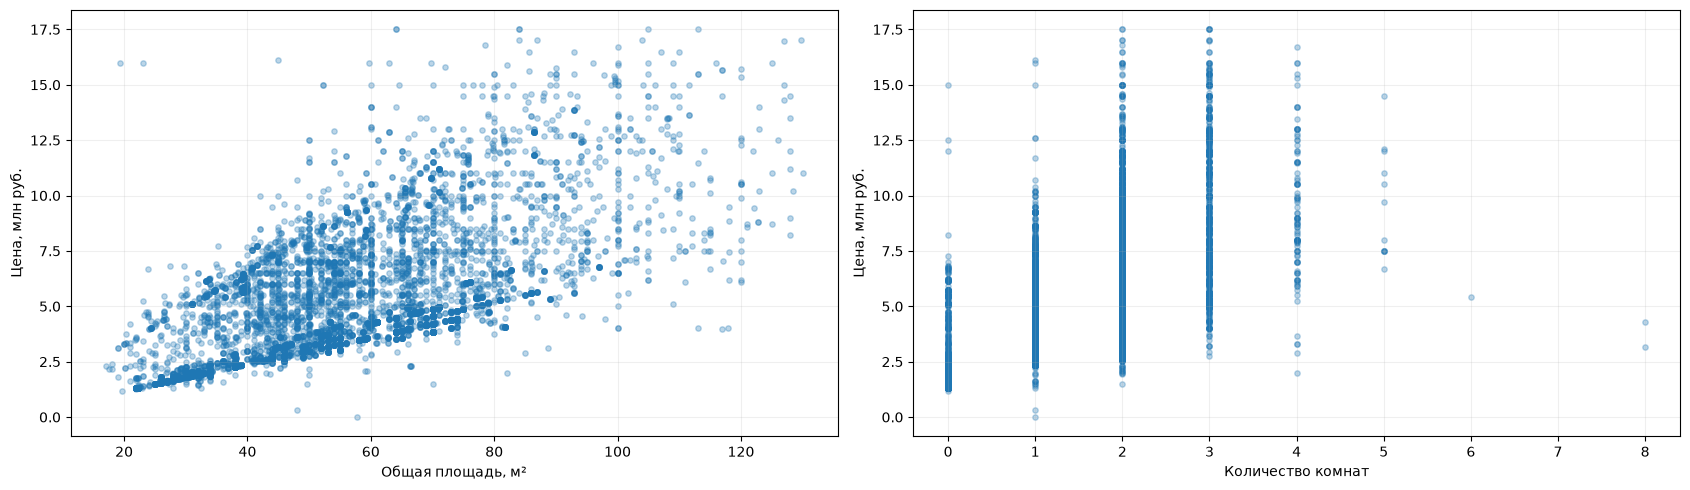

In [15]:
# сравниваем цену с площадью, комнатностью и ценой за м²
features = ["Общая площадь", "rooms"]
titles = ["Общая площадь, м²", "Количество комнат"]

fig, axes = plt.subplots(1, 2, figsize=(17, 5))

for ax, feature, title in zip(axes, features, titles):
    ax.scatter(df[feature], df["price"] / 1_000_000, alpha=0.3, s=15)
    ax.set_xlabel(title)
    ax.set_ylabel("Цена, млн руб.")
    ax.ticklabel_format(axis="x", style="plain", useOffset=False)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

<a id="conclusions"></a>
## 10. Выводы

В выполненном примере RMSE с утечкой составила примерно **1,41 млн рублей**, после исключения цены за м² примерно **2,06 млн рублей**. Первый результат выглядит лучше, но использует информацию о правильном ответе. Второй показывает качество модели после удаления этой утечки. При изменении данных числа могут измениться.

- Мы загрузили готовые данные, выделили признаки и цену, разделили квартиры на train и test.
- Через `fit` обучили две линейные регрессии, через `predict` получили прогнозы.
- MSE показывает средний квадрат ошибки, RMSE выражает масштаб ошибок в рублях.
- Цена за м² рассчитана из правильного ответа. Она создаёт утечку, даже если тестовые квартиры не участвовали в обучении.
- После исключения этого признака оцениваем прогноз по оставшимся характеристикам. Увеличение ошибки не означает, что признак нужно вернуть: важна доступность информации при настоящем прогнозе.

**Ограничение учебного примера:** таблица уже подготовлена в занятии 2 целиком. Для строгой оценки заполнение пропусков и другие настройки предобработки нужно определять только по train, затем применять к test. Здесь мы отдельно изучили утечку через цену за м².